# Итоговый проект: Python для анализа данных

Анализ продаж по таблицам `orders.xlsx` и `products.xlsx`.

Задание: https://app.simulative.ru/course/14/1090  
Данные: https://disk.yandex.ru/d/EkSfw6q9qLKmNA

Нужно сравнить продажи по категориям, рассчитать средний чек, долю промо,
маржу и сделать ABC-анализ по подкатегориям. Под количеством продаж понимаю
сумму `quantity`, а под суммой продаж — `quantity * price`.

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
from IPython.display import display

DATA = Path('data')
RESULTS = Path('results')
RESULTS.mkdir(exist_ok=True)
pd.set_option('display.max_rows', 120)
pd.set_option('display.max_columns', 12)
pd.set_option('display.float_format', '{:,.2f}'.format)
plt.rcParams.update({'font.family': 'DejaVu Sans', 'font.size': 11})

orders = pd.read_excel(DATA / 'orders.xlsx')
products = pd.read_excel(DATA / 'products.xlsx')
display(orders.head())
display(products.head())

,order_id,accepted_at,product_id,quantity,regular_price,price,cost_price
0,1517514900,2022-01-13 16:48:19,17122,1,169,169,74
1,1517430051,2022-01-13 16:46:53,17122,1,169,169,74
2,1517578174,2022-01-13 18:12:30,17122,1,169,169,74
3,1517466327,2022-01-13 15:11:12,22199,1,219,219,130
4,1517429157,2022-01-13 19:15:59,22199,1,219,219,130


,product_id,level1,level2,name
0,1,Гигиена,Бритье,Кассеты для бритья Gillette Fusion ProGlide Po...
1,2,Мучные кондитерские изделия,Мучные кондитерские изделия,Печенье Бодрость
2,3,Мясная гастрономия,"Сосиски, сардельки",Сосиски Стародворье
3,4,Чай,Черный чай,Чай Азерчай
4,5,Безалкогольные напитки,Соковая продукция,Морс Valio


## Подготовка и проверка данных

Сначала проверяю типы, пропуски и повторы. Товары соединяю с продажами по
`product_id`. У каждого ID в справочнике должна быть одна строка, иначе
соединение может искусственно увеличить продажи.

In [2]:
orders['accepted_at'] = pd.to_datetime(orders['accepted_at'], errors='raise')
display(pd.DataFrame({'Тип': orders.dtypes.astype(str), 'Пропуски': orders.isna().sum()}))
display(pd.DataFrame({'Тип': products.dtypes.astype(str), 'Пропуски': products.isna().sum()}))
print('Строк продаж:', len(orders))
print('Строк справочника:', len(products))
print('Полных дублей в orders:', orders.duplicated().sum())
print('Полных дублей в products:', products.duplicated().sum())
print('Повторяющихся product_id в справочнике:', products['product_id'].duplicated().sum())
print('Период:', orders['accepted_at'].min(), '—', orders['accepted_at'].max())

assert orders.notna().all().all()
assert products[['product_id', 'level1', 'level2']].notna().all().all()
assert products['product_id'].is_unique
assert (orders['quantity'] > 0).all()
assert (orders[['regular_price', 'price', 'cost_price']] >= 0).all().all()
assert orders.groupby('order_id')['accepted_at'].nunique().max() == 1

orders['revenue'] = orders['quantity'] * orders['price']
orders['cost'] = orders['quantity'] * orders['cost_price']
orders['margin'] = orders['revenue'] - orders['cost']
joined = orders.merge(products, on='product_id', how='left', validate='many_to_one', indicator=True)
unknown = joined['_merge'].eq('left_only')
print('Без справочника: строк', unknown.sum(),
      ', штук', joined.loc[unknown, 'quantity'].sum(),
      ', выручка', joined.loc[unknown, 'revenue'].sum(), 'руб.')
sales = joined.loc[~unknown].drop(columns='_merge').copy()
print('Для анализа категорий: строк', len(sales), ', штук', sales['quantity'].sum())
print('Продаж ниже себестоимости:', (sales['price'] < sales['cost_price']).sum())
print('Продаж дороже регулярной цены:', (sales['price'] > sales['regular_price']).sum())

,Тип,Пропуски
order_id,int64,0
accepted_at,datetime64[us],0
product_id,int64,0
quantity,int64,0
regular_price,int64,0
price,int64,0
cost_price,int64,0


,Тип,Пропуски
product_id,int64,0
level1,str,0
level2,str,0
name,str,212


Строк продаж: 3323
Строк справочника: 40152
Полных дублей в orders: 0
Полных дублей в products: 0
Повторяющихся product_id в справочнике: 0
Период: 2022-01-13 08:00:30 — 2022-01-13 22:58:29
Без справочника: строк 305 , штук 373 , выручка 51304 руб.
Для анализа категорий: строк 3018 , штук 3732
Продаж ниже себестоимости: 38
Продаж дороже регулярной цены: 0


Всего 3 323 строки продаж и 40 152 товара в справочнике. Полных дублей нет.
В названиях товаров есть 212 пропусков, но категории заполнены. Для расчётов
название товара не требуется, поэтому такие строки сохраняю.

Все продажи относятся к **13.01.2022**. В справочнике отсутствуют товары из
305 строк продаж: это 373 штуки на 51 304 руб. Для заданий по категориям
остаются 3 018 строк и 3 732 штуки. Для среднего чека использую исходную
таблицу `orders`, чтобы не потерять часть стоимости чеков.

38 строк в соединённой таблице проданы ниже закупочной цены. Их не удаляю:
они влияют на фактическую маржу. По одному дню нельзя сделать вывод об
устойчивом спросе или сезонности.

## 1. Самая ходовая товарная группа

Суммирую `quantity` по `level1`. Показываю все категории справочника,
в том числе категории без продаж за этот день.

,"Количество, шт."
Категория,
Безалкогольные напитки,534
Молочная продукция,483
Свежие овощи,262
Кулинария,250
Бакалея,239
Хлеб и хлебобулочные изделия,218
Снэки,212
Свежие фрукты,184
Замороженная продукция,175


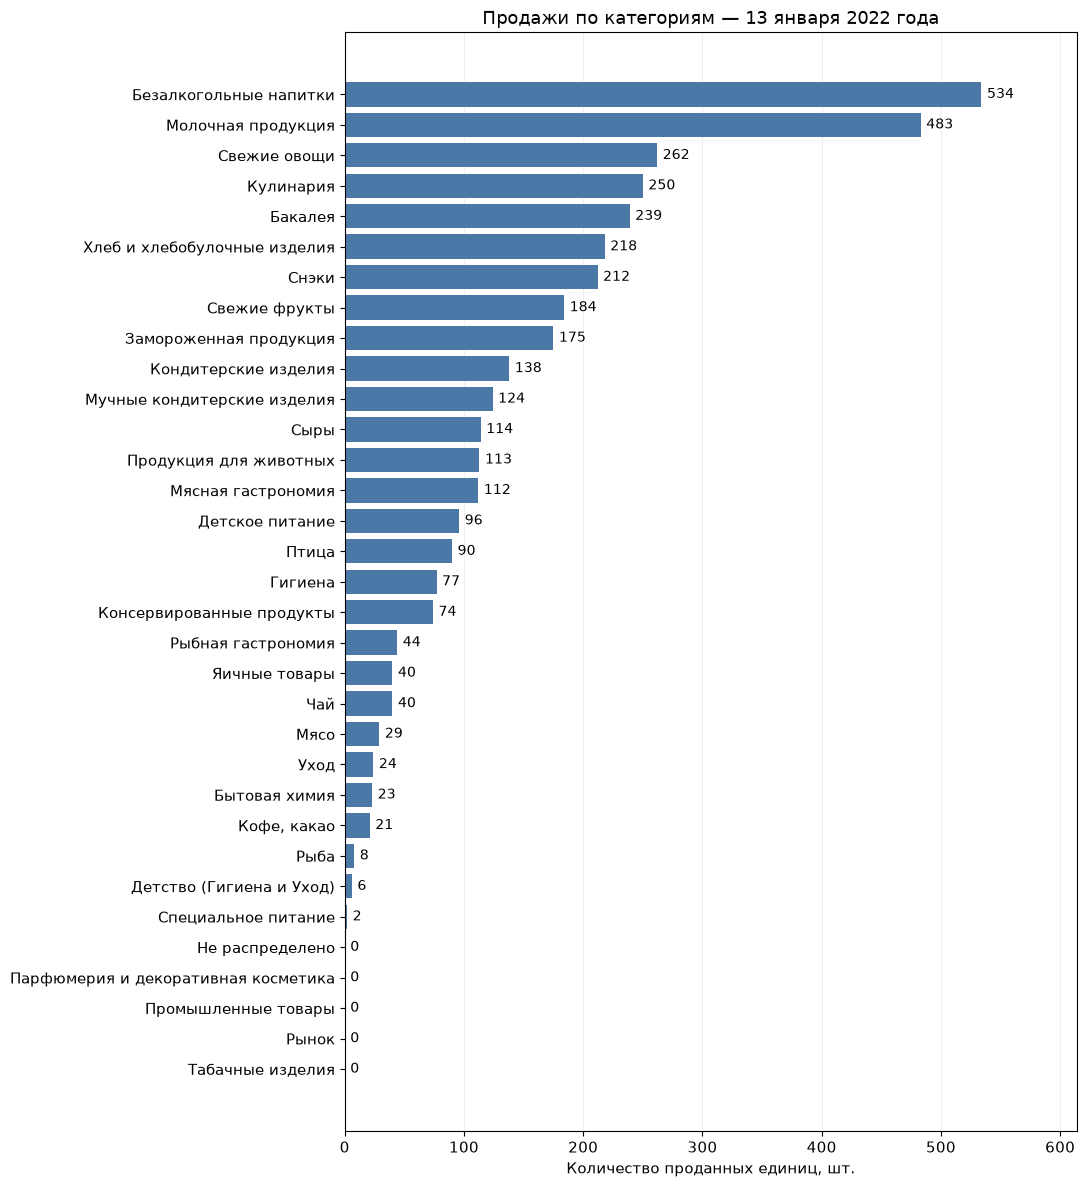

In [3]:
all_categories = sorted(products['level1'].unique())
category_quantity = (sales.groupby('level1')['quantity'].sum()
                     .reindex(all_categories, fill_value=0)
                     .sort_values(ascending=False)
                     .rename('Количество, шт.').to_frame())
category_quantity.index.name = 'Категория'
display(category_quantity)
category_quantity.to_csv(RESULTS / '01_categories.csv', encoding='utf-8-sig')

fig, ax = plt.subplots(figsize=(11, 12))
bars = ax.barh(category_quantity.index, category_quantity.iloc[:, 0], color='#4c78a8')
ax.invert_yaxis()
ax.bar_label(bars, padding=4, fontsize=10)
ax.set_xlim(0, category_quantity.iloc[:, 0].max() * 1.15)
ax.set_xlabel('Количество проданных единиц, шт.')
ax.set_title('Продажи по категориям — 13 января 2022 года')
ax.grid(axis='x', alpha=0.2)
ax.set_axisbelow(True)
fig.tight_layout()
fig.savefig(RESULTS / '01_categories.png', dpi=160, bbox_inches='tight')
plt.show()

**Больше всего продано безалкогольных напитков — 534 штуки.** Далее идут
молочная продукция — 483 штуки и свежие овощи — 262 штуки.
У пяти категорий справочника в этой выборке нет продаж. Это не означает,
что они не продаются в другие дни.

## 2. Распределение продаж по подкатегориям

Для каждой пары `level1` и `level2` считаю количество и долю внутри своей
категории. В таблицу включаю подкатегории, по которым были продажи.

In [4]:
subcategory_quantity = (sales.groupby(['level1', 'level2'], as_index=False)['quantity'].sum())
category_totals = subcategory_quantity.groupby('level1')['quantity'].transform('sum')
subcategory_quantity['share_pct'] = subcategory_quantity['quantity'] / category_totals * 100
subcategory_quantity = subcategory_quantity.sort_values(['level1', 'quantity'], ascending=[True, False])
distribution = subcategory_quantity.rename(columns={
    'level1': 'Категория', 'level2': 'Подкатегория',
    'quantity': 'Количество, шт.', 'share_pct': 'Доля внутри категории, %'})
display(distribution.reset_index(drop=True))
distribution.to_csv(RESULTS / '02_subcategories.csv', index=False, encoding='utf-8-sig')

assert np.allclose(subcategory_quantity.groupby('level1')['share_pct'].sum(), 100)
print('Ведущие подкатегории безалкогольных напитков:')
display(distribution.loc[distribution['Категория'].eq('Безалкогольные напитки')])

,Категория,Подкатегория,"Количество, шт.","Доля внутри категории, %"
0,Бакалея,Сухие блюда быстрого приготовления,38,15.90
1,Бакалея,"Крупы, бобовые",30,12.55
2,Бакалея,Зерновые для завтраков,24,10.04
3,Бакалея,Макаронные изделия,24,10.04
4,Бакалея,Соусы,24,10.04
5,Бакалея,Ингредиенты для готовки,21,8.79
6,Бакалея,Пряности,21,8.79
7,Бакалея,Мука и мучные смеси,19,7.95
8,Бакалея,Растительные масла,18,7.53
9,Бакалея,Сахар,11,4.60


Ведущие подкатегории безалкогольных напитков:


,Категория,Подкатегория,"Количество, шт.","Доля внутри категории, %"
13,Безалкогольные напитки,Напитки,252,47.19
12,Безалкогольные напитки,Воды питьевые,162,30.34
14,Безалкогольные напитки,Соковая продукция,82,15.36
11,Безалкогольные напитки,Воды минеральные,38,7.12


Доли рассчитаны внутри каждой категории: их сумма составляет 100%.
У безалкогольных напитков на подкатегорию «Напитки» приходится 252 штуки
(47,19%), на питьевую воду — 162 (30,34%), на соковую продукцию — 82
(15,36%), на минеральную воду — 38 (7,12%). Вместе «Напитки» и питьевая
вода обеспечивают 77,53% количества в этой категории.

## 3. Средний чек 13 января 2022 года

Сначала считаю стоимость каждой строки: `quantity * price`. Затем складываю
строки одного `order_id` и нахожу среднее по чекам. Средняя цена строки
или товара не является средним чеком.

In [5]:
day_orders = orders.loc[orders['accepted_at'].dt.date == pd.Timestamp('2022-01-13').date()]
checks = day_orders.groupby('order_id')['revenue'].sum()
average_check = checks.mean()
check_result = pd.DataFrame({
    'Дата': ['2022-01-13'], 'Количество чеков': [checks.size],
    'Выручка, руб.': [checks.sum()], 'Средний чек, руб.': [average_check]})
display(check_result)
check_result.to_csv(RESULTS / '03_average_check.csv', index=False, encoding='utf-8-sig')
print(f'Средний чек: {average_check:.2f} руб.')

,Дата,Количество чеков,"Выручка, руб.","Средний чек, руб."
0,2022-01-13,544,498107,915.64


Средний чек: 915.64 руб.


**Средний чек — 915,64 руб.** Это 498 107 руб. выручки, разделённые на 544 чека.
В расчёт вошли все товары, включая отсутствующие в справочнике.

## 4. Доля промо в категории «Сыры»

По условию промо — продажа, у которой фактическая цена не равна регулярной.
Долю считаю по количеству штук, а не по числу строк или выручке.

,Тип продажи,"Количество, шт.","Доля, %"
0,Промо,35,30.70
1,Без промо,79,69.30


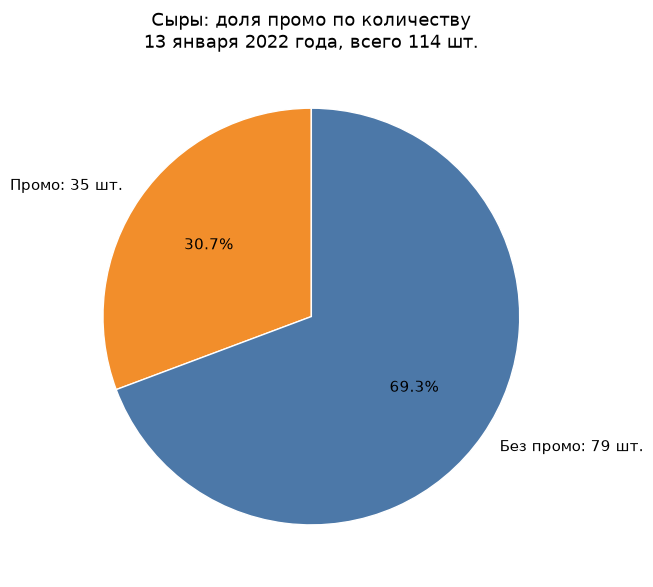

In [6]:
cheese = sales.loc[sales['level1'].eq('Сыры')].copy()
cheese['promo'] = cheese['price'].ne(cheese['regular_price'])
promo_quantity = cheese.groupby('promo')['quantity'].sum().reindex([True, False], fill_value=0)
promo_result = pd.DataFrame({
    'Тип продажи': ['Промо', 'Без промо'],
    'Количество, шт.': promo_quantity.to_numpy()})
promo_result['Доля, %'] = promo_result['Количество, шт.'] / promo_result['Количество, шт.'].sum() * 100
display(promo_result)
promo_result.to_csv(RESULTS / '04_cheese_promo.csv', index=False, encoding='utf-8-sig')

fig, ax = plt.subplots(figsize=(7, 6))
ax.pie(promo_result['Количество, шт.'],
       labels=[f'{name}: {amount} шт.' for name, amount in
               zip(promo_result['Тип продажи'], promo_result['Количество, шт.'])],
       autopct='%1.1f%%', startangle=90, colors=['#f28e2b', '#4c78a8'],
       wedgeprops={'edgecolor': 'white'})
ax.set_title('Сыры: доля промо по количеству\n13 января 2022 года, всего 114 шт.')
fig.tight_layout()
fig.savefig(RESULTS / '04_cheese_promo.png', dpi=160, bbox_inches='tight')
plt.show()

**Промо составляют 30,70% продаж сыров: 35 из 114 штук.** Без промо продано
79 штук — 69,30%. Эти данные описывают долю промо, но не доказывают,
насколько скидки увеличили продажи: для этого нужны данные для сравнения.

## 5. Маржа по категориям

Маржа в рублях = выручка − закупочная стоимость =
`sum(quantity * (price - cost_price))`.

Маржа в процентах = маржа в рублях / выручка × 100%.
В знаменателе использую выручку, а не себестоимость: иначе получилась бы наценка.
Это валовая маржа без учёта доставки, зарплат и других операционных расходов.

,"Выручка, руб.","Закупочная стоимость, руб.","Маржа, руб.","Маржа, %"
Категория,,,,
Безалкогольные напитки,46107,25734,20373,44.19
Кулинария,40840,22388,18452,45.18
Замороженная продукция,27714,14615,13099,47.26
Молочная продукция,37582,25089,12493,33.24
Мясная гастрономия,24150,13920,10230,42.36
Снэки,22477,12895,9582,42.63
Свежие овощи,33222,24216,9006,27.11
Бакалея,21766,13589,8177,37.57
Свежие фрукты,27009,19130,7879,29.17


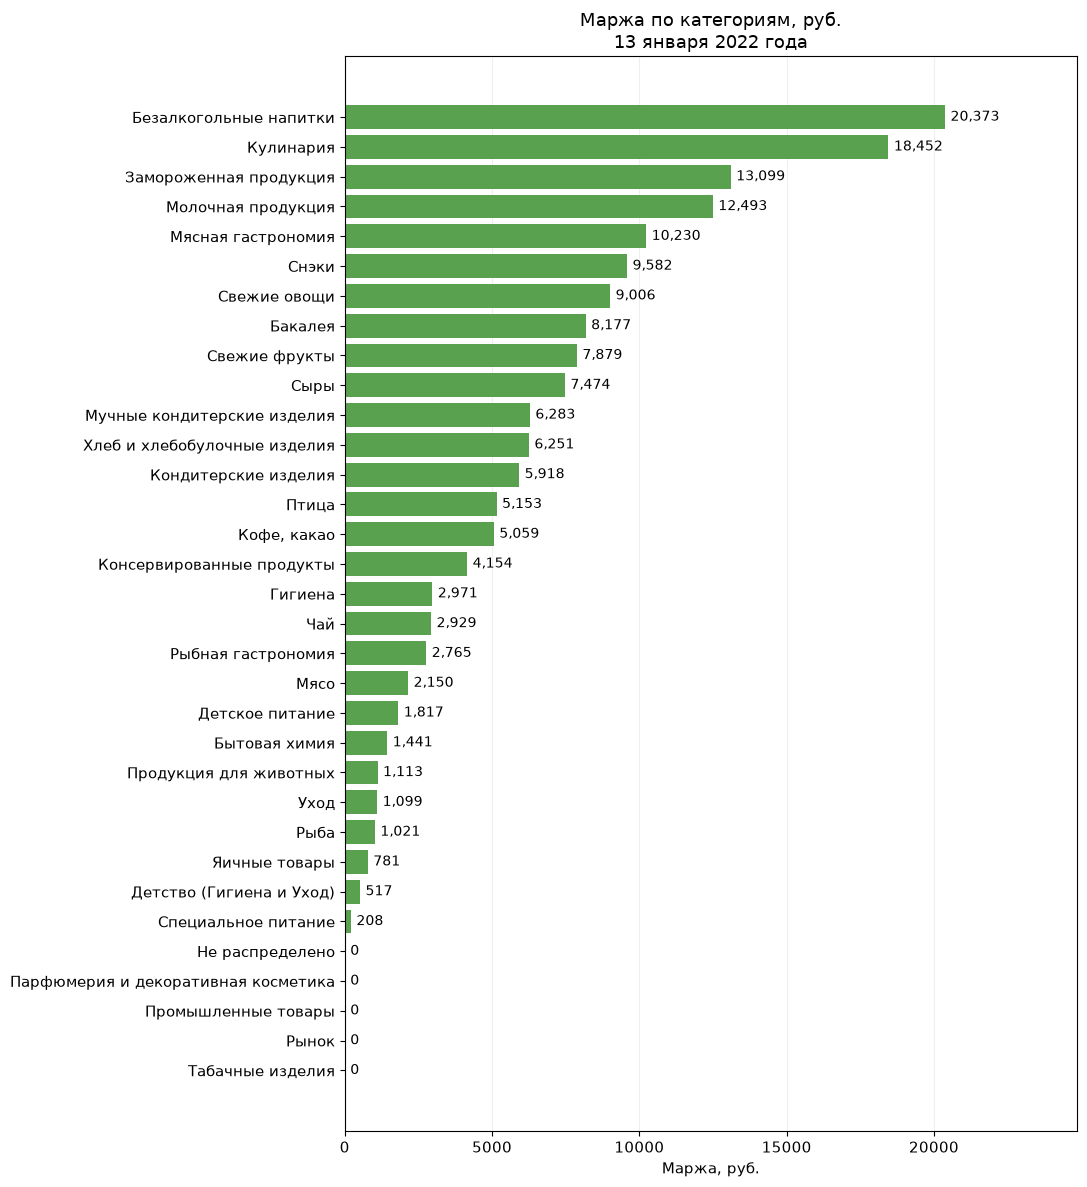

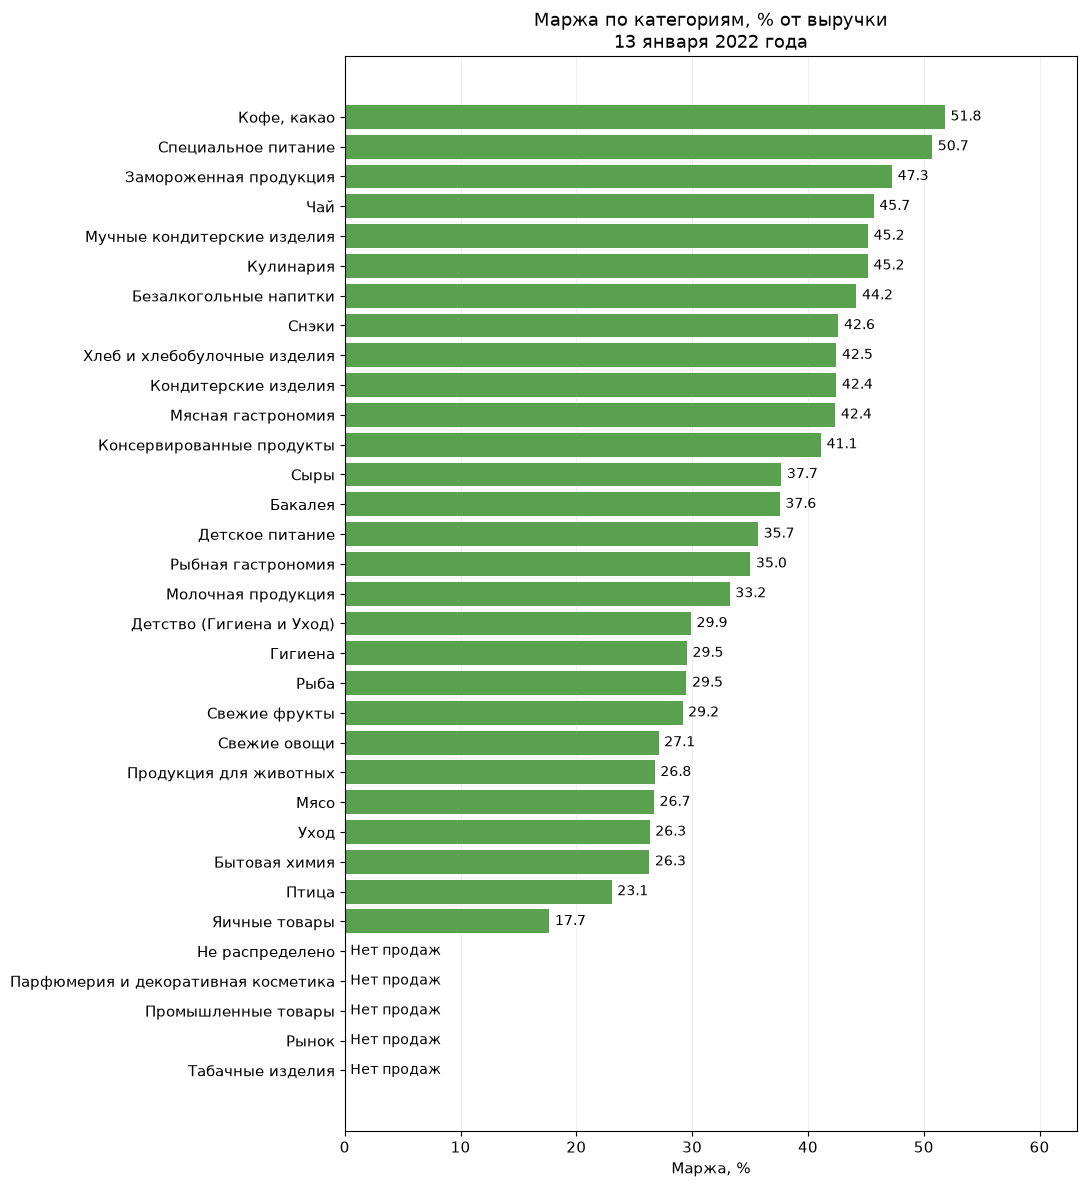

In [7]:
margin = (sales.groupby('level1')[['revenue', 'cost', 'margin']].sum()
          .reindex(all_categories, fill_value=0))
margin['margin_pct'] = margin['margin'] / margin['revenue'].replace(0, np.nan) * 100
margin = margin.sort_values('margin', ascending=False)
margin_table = margin.rename(columns={
    'revenue': 'Выручка, руб.', 'cost': 'Закупочная стоимость, руб.',
    'margin': 'Маржа, руб.', 'margin_pct': 'Маржа, %'})
margin_table.index.name = 'Категория'
display(margin_table)
margin_table.to_csv(RESULTS / '05_margin.csv', encoding='utf-8-sig')

for column, title, xlabel, filename in [
    ('margin', 'Маржа по категориям, руб.', 'Маржа, руб.', '05_margin_rubles.png'),
    ('margin_pct', 'Маржа по категориям, % от выручки', 'Маржа, %', '05_margin_percent.png')]:
    chart = margin[column].sort_values(ascending=False, na_position='last')
    fig, ax = plt.subplots(figsize=(11, 12))
    bars = ax.barh(chart.index, chart.fillna(0), color='#59a14f')
    labels = ['Нет продаж' if pd.isna(value) else f'{value:,.1f}' if column == 'margin_pct'
              else f'{value:,.0f}' for value in chart]
    ax.bar_label(bars, labels=labels, padding=4, fontsize=10)
    ax.invert_yaxis()
    ax.set_xlim(0, chart.max() * 1.22)
    ax.set_xlabel(xlabel)
    ax.set_title(title + '\n13 января 2022 года')
    ax.grid(axis='x', alpha=0.2)
    ax.set_axisbelow(True)
    fig.tight_layout()
    fig.savefig(RESULTS / filename, dpi=160, bbox_inches='tight')
    plt.show()

Самая большая маржа в рублях у **безалкогольных напитков — 20 373 руб.**,
затем у кулинарии — 18 452 руб. По процентной марже лидирует
**«Кофе, какао» — 51,83%**, хотя по абсолютной марже эта категория ниже.

Для категорий без продаж маржа в рублях равна нулю, а процент не определён:
выручка равна нулю. На графике это отмечено как «Нет продаж».

## 6. ABC-анализ по подкатегориям

Отдельно ранжирую подкатегории по количеству и по фактической выручке.
Единица анализа — пара «категория, подкатегория».

Правило: сортирую показатель по убыванию и считаю накопленную долю.
До 80% включительно — A, от 80% до 95% включительно — B, свыше 95% — C.
Подкатегория, пересекающая границу, относится к следующей группе, поэтому
доля группы A может быть немного меньше 80%. При равных значениях порядок
задаётся названиями категории и подкатегории.

Анализирую подкатегории с продажами. По одному дню не стоит принимать
окончательное решение об исключении подкатегорий из ассортимента.

In [8]:
subcategory_sales = sales.groupby(['level1', 'level2'], as_index=False).agg(
    quantity=('quantity', 'sum'), revenue=('revenue', 'sum'))

def abc_analysis(table, metric):
    result = table[['level1', 'level2', metric]].copy()
    result = result.sort_values([metric, 'level1', 'level2'], ascending=[False, True, True])
    result['share'] = result[metric] / result[metric].sum()
    result['cumulative_share'] = result['share'].cumsum()
    result['group'] = np.select(
        [result['cumulative_share'] <= 0.80, result['cumulative_share'] <= 0.95],
        ['A', 'B'], default='C')
    return result

abc_quantity = abc_analysis(subcategory_sales, 'quantity')
abc_revenue = abc_analysis(subcategory_sales, 'revenue')
abc = abc_quantity.merge(abc_revenue, on=['level1', 'level2'], validate='one_to_one',
                         suffixes=('_quantity', '_revenue'))
abc['combined_group'] = abc['group_quantity'] + abc['group_revenue']
abc = abc.sort_values(['revenue', 'level1', 'level2'], ascending=[False, True, True])
abc_result = abc.rename(columns={
    'level1': 'Категория', 'level2': 'Подкатегория',
    'quantity': 'Количество, шт.', 'revenue': 'Выручка, руб.',
    'share_quantity': 'Доля количества', 'cumulative_share_quantity': 'Накопленная доля количества',
    'group_quantity': 'ABC количества', 'share_revenue': 'Доля выручки',
    'cumulative_share_revenue': 'Накопленная доля выручки', 'group_revenue': 'ABC выручки',
    'combined_group': 'Итоговая группа'})
display(abc_result.reset_index(drop=True))
abc_result.to_csv(RESULTS / '06_abc.csv', index=False, encoding='utf-8-sig')
print('Число подкатегорий по сочетаниям групп:')
display(pd.crosstab(abc['group_quantity'], abc['group_revenue']).reindex(
    index=['A', 'B', 'C'], columns=['A', 'B', 'C'], fill_value=0))
print('Подкатегории AA с наибольшей выручкой:')
display(abc_result.loc[abc_result['Итоговая группа'].eq('AA'),
                       ['Подкатегория', 'Количество, шт.', 'Выручка, руб.', 'Итоговая группа']].head(5))

,Категория,Подкатегория,"Количество, шт.",Доля количества,Накопленная доля количества,ABC количества,"Выручка, руб.",Доля выручки,Накопленная доля выручки,ABC выручки,Итоговая группа
0,Кулинария,Готовые блюда,248,0.07,0.13,A,40356,0.09,0.09,A,AA
1,Безалкогольные напитки,Напитки,252,0.07,0.07,A,24123,0.05,0.14,A,AA
2,Птица,Мясо птицы охлажденное,90,0.02,0.53,A,22349,0.05,0.19,A,AA
3,Свежие овощи,"Тепличные овощи, грибы",105,0.03,0.48,A,18329,0.04,0.24,A,AA
4,Снэки,Снэки соленые,180,0.05,0.24,A,17293,0.04,0.27,A,AA
5,Свежие фрукты,"Цитрусовые, семечковые и прочие плоды",108,0.03,0.43,A,16818,0.04,0.31,A,AA
6,Замороженная продукция,Замороженные полуфабрикаты,73,0.02,0.64,A,15374,0.03,0.35,A,AA
7,Молочная продукция,Молоко и сливки,147,0.04,0.37,A,14902,0.03,0.38,A,AA
8,Свежие овощи,"Корнеплоды, зелень и прочие овощи",157,0.04,0.33,A,14893,0.03,0.41,A,AA
9,Хлеб и хлебобулочные изделия,Хлеб и хлебобулочные изделия,218,0.06,0.19,A,14724,0.03,0.45,A,AA


Число подкатегорий по сочетаниям групп:


group_revenue,A,B,C
group_quantity,,,
A,23,5,2
B,9,15,4
C,0,10,32


Подкатегории AA с наибольшей выручкой:


,Подкатегория,"Количество, шт.","Выручка, руб.",Итоговая группа
1,Готовые блюда,248,40356,AA
0,Напитки,252,24123,AA
12,Мясо птицы охлажденное,90,22349,AA
10,"Тепличные овощи, грибы",105,18329,AA
3,Снэки соленые,180,17293,AA


Первая буква итоговой группы относится к количеству, вторая — к выручке.
Например, AC означает высокую позицию по количеству и низкую по выручке.
Для AA важно поддерживать наличие товара: эти подкатегории входят в ведущую
группу по обоим показателям. В этой выборке **23 подкатегории AA**.
Среди них по выручке лидируют «Готовые блюда» — 40 356 руб. и «Напитки» —
24 123 руб. В группе CC — 32 подкатегории. Для CC стоит дополнительно изучить продажи за
несколько недель, наличие товара и роль подкатегории в корзине.

## Проверка итогов

Сверяю суммы после группировок с исходными продажами. Это помогает заметить
потерянные строки или размножение данных при соединении.

In [9]:
assert len(joined) == len(orders)
assert category_quantity.iloc[:, 0].sum() == sales['quantity'].sum()
assert subcategory_quantity['quantity'].sum() == sales['quantity'].sum()
assert margin['revenue'].sum() == sales['revenue'].sum()
assert margin['margin'].sum() == (sales['quantity'] * (sales['price'] - sales['cost_price'])).sum()
assert np.isclose(average_check, day_orders['revenue'].sum() / day_orders['order_id'].nunique())
assert promo_result['Количество, шт.'].sum() == cheese['quantity'].sum()
assert np.isclose(promo_result['Доля, %'].sum(), 100)
assert np.isclose(abc_quantity['share'].sum(), 1)
assert np.isclose(abc_revenue['share'].sum(), 1)
assert len(abc) == len(subcategory_sales)
assert abc['quantity'].sum() == sales['quantity'].sum()
assert abc['revenue'].sum() == sales['revenue'].sum()
print('Все сверки выполнены. Результаты сохранены в папке results.')

Все сверки выполнены. Результаты сохранены в папке results.


## Краткие выводы

- Лидер по количеству — безалкогольные напитки, 534 штуки.
- Средний чек по всей выгрузке — 915,64 руб.
- В категории «Сыры» 30,70% штук продано по промо.
- Безалкогольные напитки дают наибольшую маржу в рублях, а «Кофе, какао» — в процентах.
- ABC-анализ выполнен для 100 подкатегорий с продажами, по количеству и выручке.

Результаты относятся только к предоставленным продажам за один день.
Данные не позволяют оценить эффект скидок или устойчивость спроса во времени.